# 04. InfraScan Dataset Cleaning, Splitting & Label Conversion

This notebook imports and runs the reusable pipeline module (`infrascan.ml.data_prep`) to perform automated data cleaning, deduplication, group splitting, and label conversion across all five crack detection datasets:

1. **SDNET2018** (Classification): Source photo group split (70/15/15) preventing spatial crop leakage across splits.
2. **concrete_crack_cls** (Classification): Stratified 70/15/15 split by class label.
3. **RDD2022** (Object Detection): Pascal VOC XML to YOLO bounding box conversion (classes 0..3), background support, 70/15/15 split.
4. **CRACK500** (Segmentation): Pair crop images with same-name masks, check dimensions, and preserve official traincrop/valcrop/testcrop splits. Full-size and model-output folders are ignored.
5. **CFD** (Segmentation): Grayscale mask validation and benchmark `test` split (118 images).

> **Strict Safety Rule**: All raw data in `data/raw/` is treated as strictly read-only. Cleaned outputs and manifests are written exclusively to `data/processed/`.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import importlib

base_dir = Path(r"D:\Infosys springboards")
project_root = base_dir / "infrascan"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import ml.data_prep
importlib.reload(ml.data_prep)
from ml import data_prep
print(f"Pipeline module: {data_prep.__file__}")
print(f"Notebook Python: {sys.executable}")

Pipeline module: D:\Infosys springboards\infrascan\ml\data_prep.py
Notebook Python: D:\Infosys springboards\infrascan\ml\venv\Scripts\python.exe


## 1. Raw Dataset Inspection
Inspect the folder structure and initial file counts across all raw dataset directories.

In [2]:
base_dir = r"D:\Infosys springboards"
raw_dirs = {
    "sdnet2018": os.path.join(base_dir, "data", "raw", "sdnet2018"),
    "concrete_crack_cls": os.path.join(base_dir, "data", "raw", "concrete_crack_cls"),
    "rdd2022": os.path.join(base_dir, "data", "raw", "rdd2022"),
    "crack500": os.path.join(base_dir, "data", "raw", "crack500"),
    "cfd": os.path.join(base_dir, "data", "raw", "cfd"),
}
processed_dir = os.path.join(base_dir, "data", "processed")

# This prints the raw folder structure first, then runs cleaning, splitting, and validation.
summary_df = data_prep.main()


RAW DATASET FOLDER STRUCTURES & INITIAL INSPECTION

[+] Dataset: sdnet2018
    Path: D:\Infosys springboards\data\raw\sdnet2018
    Subdirectories (3): ['D', 'P', 'W']



Counting sdnet2018 folders: 0dir [00:00, ?dir/s]


Counting sdnet2018 folders: 10dir [00:00, 154.75dir/s]

    Total image files found: 56,092

[+] Dataset: concrete_crack_cls
    Path: D:\Infosys springboards\data\raw\concrete_crack_cls
    Subdirectories (2): ['Negative', 'Positive']



Counting concrete_crack_cls folders: 0dir [00:00, ?dir/s]


Counting concrete_crack_cls folders: 3dir [00:00, 70.06dir/s]

... (98 outputs left out)

  [OK] crack500 passed all file existence and split disjointness checks.
  [OK] CRACK500 source-photo groups remain within a single split.
[Assert] Checking cfd (118 entries)...
  [OK] cfd passed all file existence and split disjointness checks.
[Assert] Checking RDD2022 YOLO dataset structure and labels...


  [OK] RDD2022 YOLO passed: 38,384 images with matching label files. All coordinates in [0.0, 1.0].
ALL INTEGRITY ASSERTIONS PASSED SUCCESSFULLY!


[Documentation] Successfully generated D:\Infosys springboards\docs\08_dataset_cleaning.md

DATA PREPARATION PIPELINE COMPLETED SUCCESSFULLY!

Final split summary:
           dataset                          task split            class_name  count  total_in_split imbalance_ratio
         sdnet2018                classification  test               cracked   1255            8802          6.01:1
         sdnet2018                classification  test             uncracked   7547            8802          6.01:1
         sdnet2018                classification train               cracked   5996           38495          5.42:1
         sdnet2018                classification train             uncracked  32499           38495          5.42:1
         sdnet2018                classification   val               cracked   1230            8782          6.14:1
         sdnet2018                classification   val             uncracked   7552            8782          6.14:1
concrete_crack_cls      


Processed output size: 10.33 GiB
Created/updated files: 4 (full list: D:\Infosys springboards\data\processed\reports\created_files.txt)
  data\processed\reports\created_files.txt
  data\processed\reports\split_summary.csv
  data\processed\reports\split_summary.png
  docs\08_dataset_cleaning.md


## 2. Cleaning Audit & Exclusion Report
Review files and annotations excluded during automated cleaning (corrupted files, duplicate SHA-256 hashes, dimension mismatches, unsupported classes, and invalid boxes).

In [3]:
report_path = os.path.join(processed_dir, "reports", "cleaning_report.csv")
if os.path.exists(report_path):
    df_report = pd.read_csv(report_path)
    print(f"Total cleaning exclusions logged: {len(df_report)}")
    summary_table = df_report.groupby(["dataset", "reason"]).size().unstack(fill_value=0)
    display(summary_table)
else:
    print("Cleaning report not found. Run the pipeline first.")

Total cleaning exclusions logged: 12398


reason,duplicate_hash,invalid_box,source_photo_split_overlap,unsupported_class
dataset,,,,
concrete_crack_cls,1598,0,0,0
crack500,0,0,80,0
rdd2022,1,1,0,10705
sdnet2018,13,0,0,0


## 3. Visual Inspection: Converted RDD2022 YOLO Annotations
Select 5 random images from `rdd2022_yolo` and plot the normalized bounding boxes converted back to pixel coordinates, with corresponding class labels:
- `0: D00` (Longitudinal crack)
- `1: D10` (Transverse crack)
- `2: D20` (Alligator crack)
- `3: D40` (Pothole)

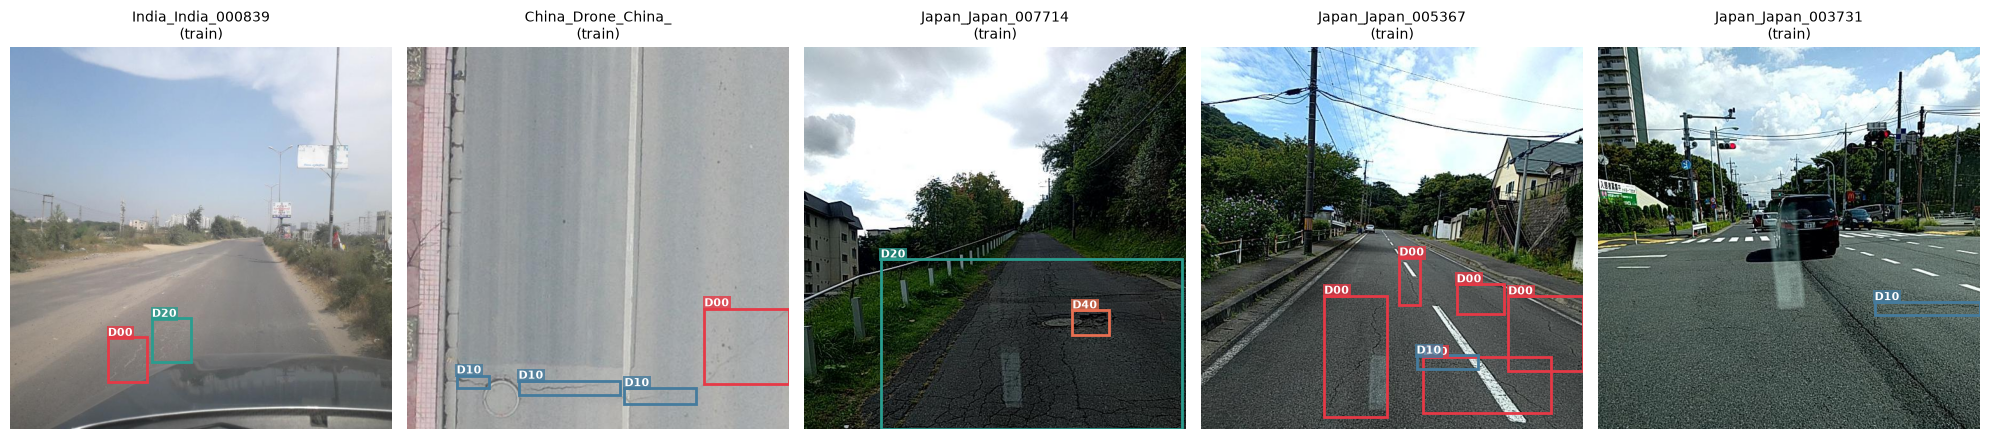

In [4]:
fig_rdd = data_prep.visualize_rdd2022_samples(processed_dir, n_samples=5, seed=42)
plt.show()

## 4. Visual Inspection: CRACK500 Segmentation Masks
Inspect 3 random image-mask pairs from `crack500.csv` showing the raw photo, binary ground truth mask, and colored crack overlay.

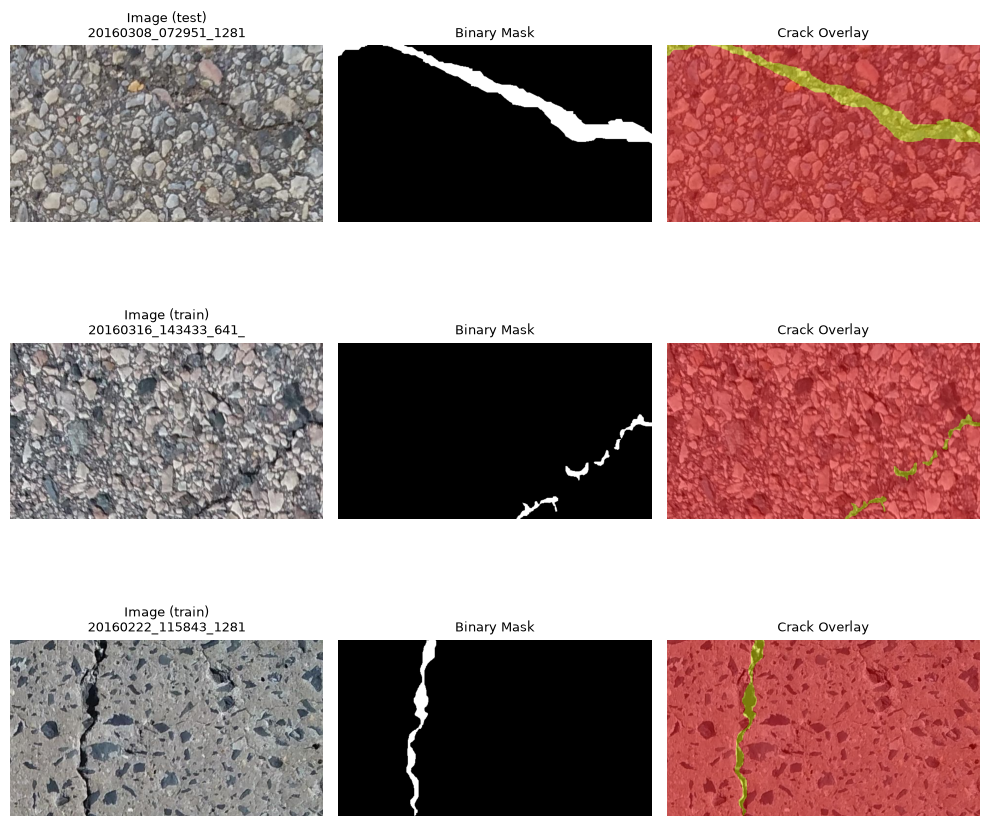

In [5]:
fig_c500 = data_prep.visualize_crack500_samples(processed_dir, n_samples=3, seed=42)
plt.show()

## 5. Pipeline Integrity Assertions
Execute strict validation checks on all processed artifacts:
1. **Zero Hash Leakage**: No SHA-256 hash appears across more than one split in any dataset.
2. **Path Verification**: Every image and mask referenced in the manifests exists on disk.
3. **YOLO Geometry & Bounds**: All coordinates are within $[0.0, 1.0]$, classes in $0..3$, and every image in `images/` has a matching `.txt` in `labels/`.

In [6]:
data_prep.run_pipeline_assertions(processed_dir)


RUNNING PIPELINE INTEGRITY ASSERTIONS
[Assert] Checking sdnet2018 (56,079 entries)...


  [OK] sdnet2018 passed all file existence and split disjointness checks.
  [OK] SDNET2018 source-photo groups remain within a single split.
[Assert] Checking concrete_crack_cls (38,402 entries)...


  [OK] concrete_crack_cls passed all file existence and split disjointness checks.
[Assert] Checking crack500 (3,288 entries)...
  [OK] crack500 passed all file existence and split disjointness checks.
  [OK] CRACK500 source-photo groups remain within a single split.
[Assert] Checking cfd (118 entries)...
  [OK] cfd passed all file existence and split disjointness checks.
[Assert] Checking RDD2022 YOLO dataset structure and labels...


  [OK] RDD2022 YOLO passed: 38,384 images with matching label files. All coordinates in [0.0, 1.0].
ALL INTEGRITY ASSERTIONS PASSED SUCCESSFULLY!


## 6. Dataset Split Summary & Class Distribution Analysis
Display the final split summary table with sample counts and imbalance ratios for each dataset and partition.

,dataset,task,split,class_name,count,total_in_split,imbalance_ratio
0,sdnet2018,classification,test,cracked,1255,8802,6.01:1
1,sdnet2018,classification,test,uncracked,7547,8802,6.01:1
2,sdnet2018,classification,train,cracked,5996,38495,5.42:1
3,sdnet2018,classification,train,uncracked,32499,38495,5.42:1
4,sdnet2018,classification,val,cracked,1230,8782,6.14:1
5,sdnet2018,classification,val,uncracked,7552,8782,6.14:1
6,concrete_crack_cls,classification,test,cracked,2952,5760,1.05:1
7,concrete_crack_cls,classification,test,uncracked,2808,5760,1.05:1
8,concrete_crack_cls,classification,train,cracked,13779,26881,1.05:1
9,concrete_crack_cls,classification,train,uncracked,13102,26881,1.05:1


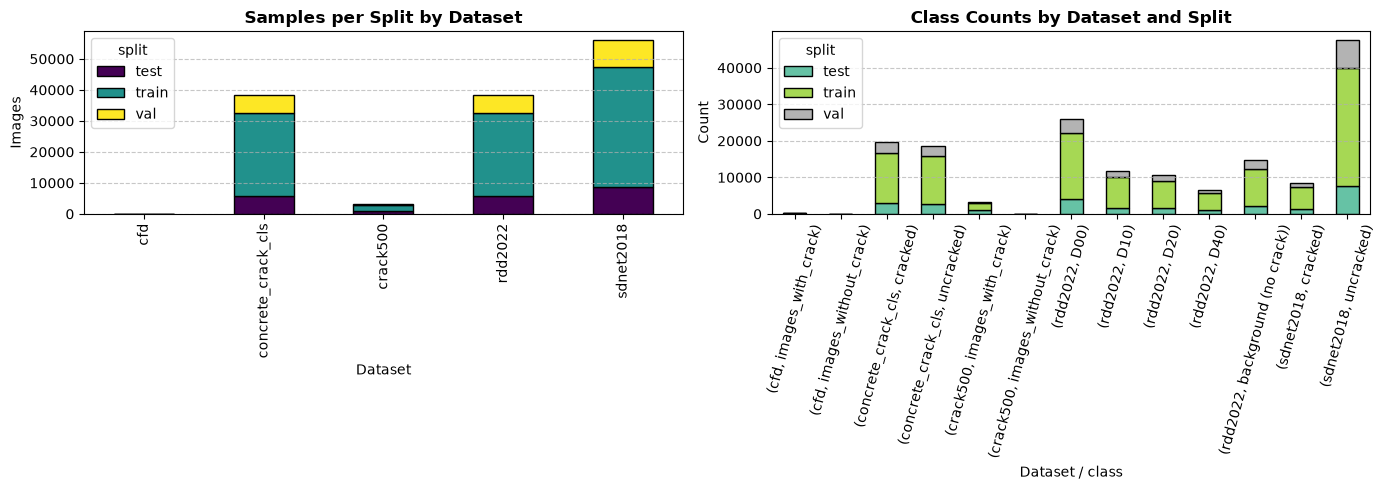

In [7]:
summary_path = os.path.join(processed_dir, "reports", "split_summary.csv")
if os.path.exists(summary_path):
    summary_df = pd.read_csv(summary_path)
    display(summary_df)
    
    fig_dist = data_prep.plot_distributions_and_splits(processed_dir)
    plt.show()
else:
    print("Split summary not found.")